In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Write your imports here

# Calculus Exercise
## Numerical Computation. Derivatives, integrals. Calculus in many dimensions

### Problem 1. Derivative and Slope at a Point
We'll warm up by visualizing how the derivative of a function relates to the slope of the function at a given point.

We can either calculate the derivative analytically (by hand) or use the numerical definition. So, let's see what a function and its derivative look like.

Write a Python function which plots a math function and its derivative.

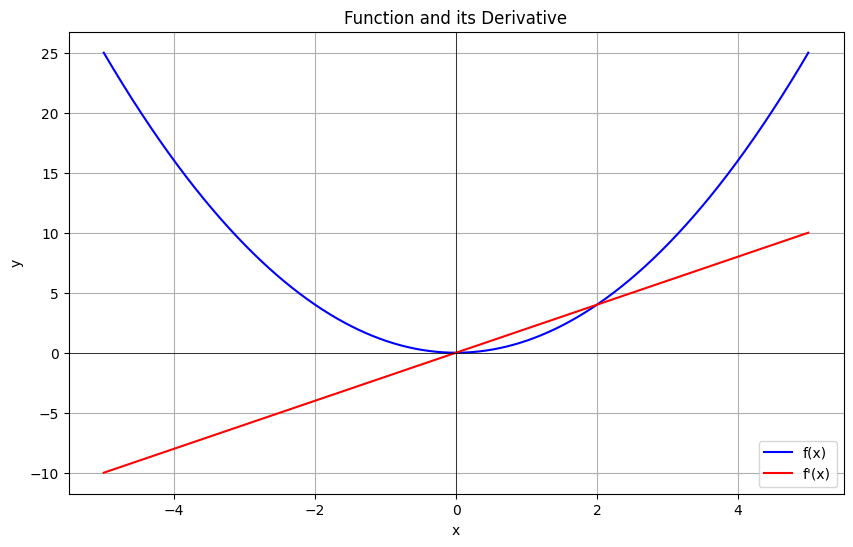

In [3]:
def calculate_derivative_at_point(function, point, precision=1e-7):
    """
    Calculates a numerical approximation of the derivative
    at the specified point.
    """
    return (function(point + precision) - function(point)) / precision


def plot_derivative(function, derivative=None, min_x=-10, max_x=10):
    """
    Plots the function and its derivative.
    """

    vectorized_function = np.vectorize(function)

    x = np.linspace(min_x, max_x, 1000)

    # Generate function values
    y = vectorized_function(x)

    # Calculate derivative values
    if derivative is None:
        dy = np.vectorize(
            lambda point: calculate_derivative_at_point(function, point)
        )(x)
    else:
        dy = np.vectorize(derivative)(x)

    # Plot function and derivative
    plt.figure(figsize=(10, 6))

    plt.plot(x, y, label="f(x)", color="blue")
    plt.plot(x, dy, label="f'(x)", color="red")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Function and its Derivative")

    plt.axhline(0, color="black", linewidth=0.5)
    plt.axvline(0, color="black", linewidth=0.5)

    plt.grid(True)
    plt.legend()
    plt.show()


# Test
f = lambda x: x ** 2

plot_derivative(f, min_x=-5, max_x=5)

Let's now test with out favourite function: $y = x^2$ whose derivative is $y' = 2x$. If you've worked correctly, both of the following plots should be the same.

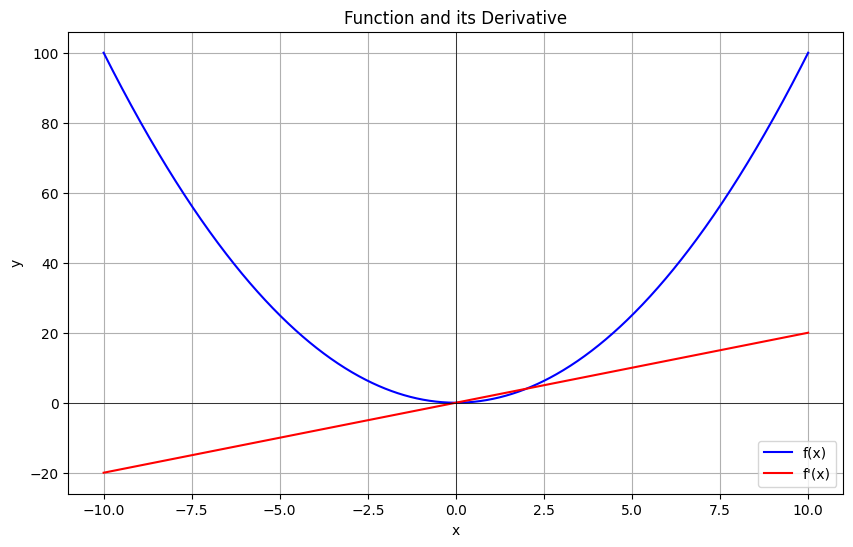

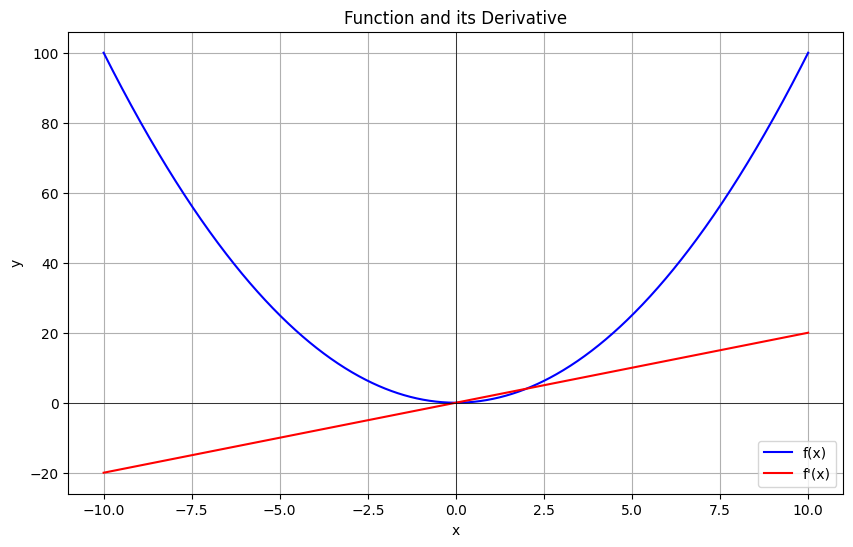

In [4]:
plot_derivative(lambda x: x ** 2, lambda x: 2 * x) # The derivative is calculated by hand
plot_derivative(lambda x: x ** 2) # The derivative is not pre-calculated, should be calculated inside the function

Let's try one more: $y = \sin(x)$, $y'= \cos(x)$.

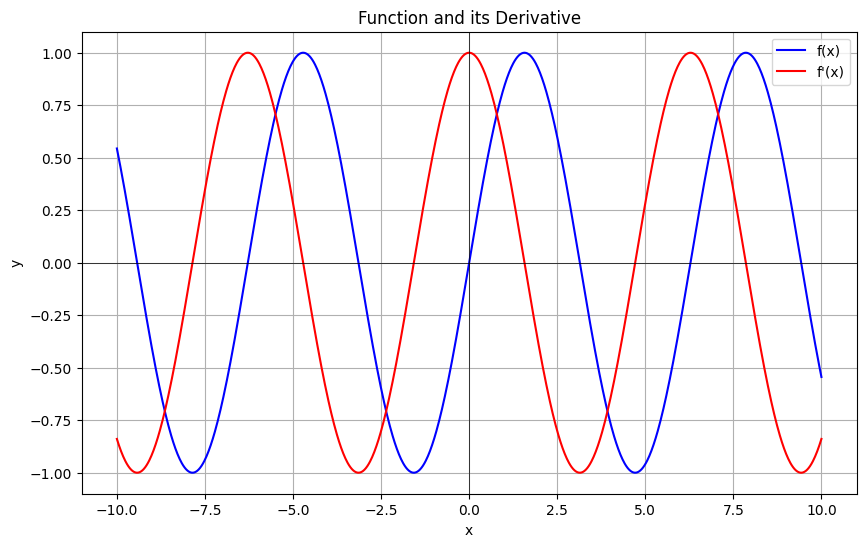

In [5]:
plot_derivative(np.sin)

These plots may look nice but they don't reflect the idea of **slope at a point** very well. Now that we're sure our functions are working, let's actually calculate the derivative at **one point** and see that it is, indeed, equal to the slope of the function at that point.

#### How to plot the tangent line?
We need to find the line equation first. 

We're given the derivative, which is equal to the slope of the line. In the line equation $y = ax + b$, the slope is $a$. We now have to find $b$. We're given a point $P(x_P; y_P)$ through which the line passes. Substitute $x_P$ and $y_P$:
$$ y_P = ax_P + b $$

$$ b = y_P - ax_P $$

Now that we have $a$ and $b$, we can plot the line given by $y = ax + b$. The parameter $b$ is sometimes called "y-intercept" (or "intercept").

Now we can copy the code from the previous function. This time, however, we won't plot the entire range, only one value of the derivative. We'll also show the point where we're calculating.

In [6]:
def plot_derivative_at_point(function, point, derivative=None,
                             min_x=-10, max_x=10):
    """
    Plots the function and its tangent line at a given point.
    """
    vectorized_function = np.vectorize(function)

    x = np.linspace(min_x, max_x, 1000)
    y = vectorized_function(x)

    slope = 0  # Slope of the tangent line

    if derivative is None:
        slope = calculate_derivative_at_point(function, point)
    else:
        slope = derivative(point)

    intercept = function(point) - slope * point

    tangent_line_x = np.linspace(point - 2, point + 2, 10)
    tangent_line_y = slope * tangent_line_x + intercept

    plt.figure(figsize=(10, 6))

    plt.plot(x, y, label="Function f(x)", color="blue")
    plt.plot(tangent_line_x, tangent_line_y,
             label="Tangent line", color="red")

    plt.scatter(point, function(point),
                color="green", s=100, zorder=5)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Derivative at a Point")
    plt.legend()
    plt.grid(True)

    plt.show()

    print(f"Slope: {slope:.4f}")
    print(f"Intercept: {intercept:.4f}")

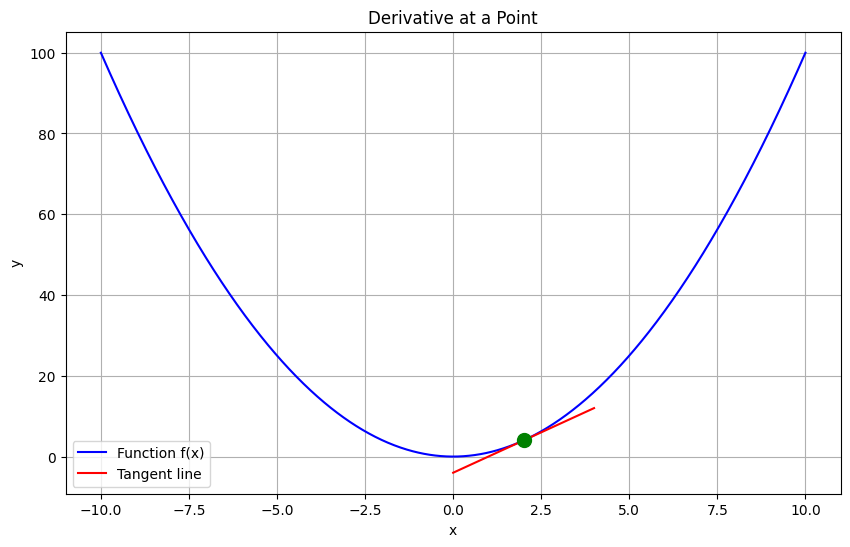

Slope: 4.0000
Intercept: -4.0000


In [7]:
plot_derivative_at_point(lambda x: x ** 2, 2)

Looks like it! Let's zoom in to confirm:

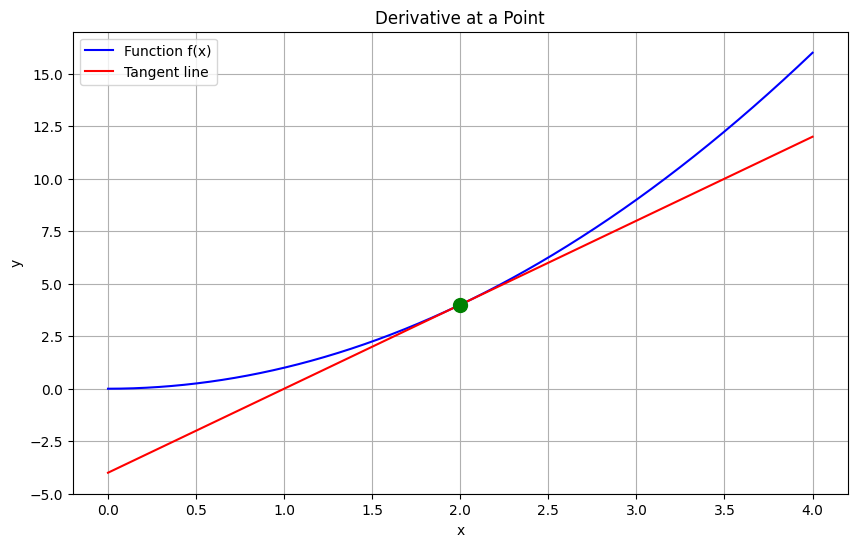

Slope: 4.0000
Intercept: -4.0000


In [8]:
plot_derivative_at_point(lambda x: x ** 2, 2, min_x = 0, max_x = 4)

Let's also plot several tangents to the same function. Note that this will create many graphs by default. You can plot them all at once if you wish.

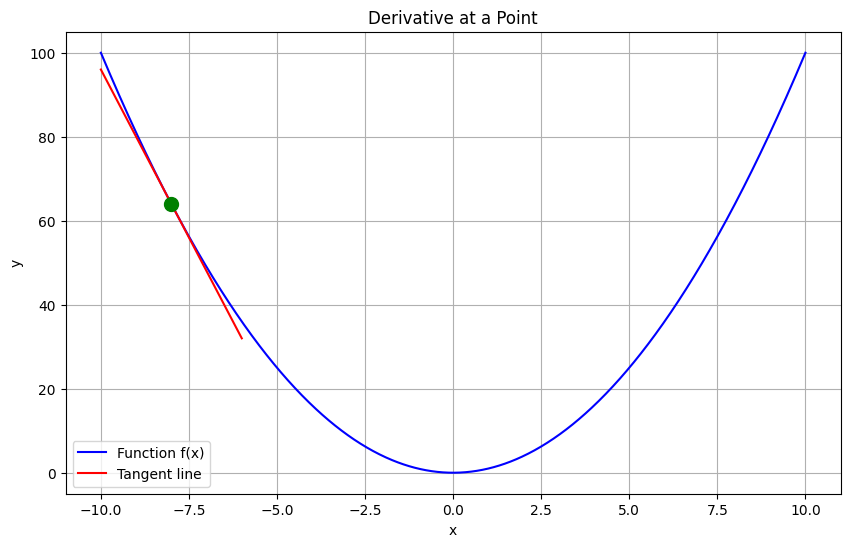

Slope: -16.0000
Intercept: -64.0000


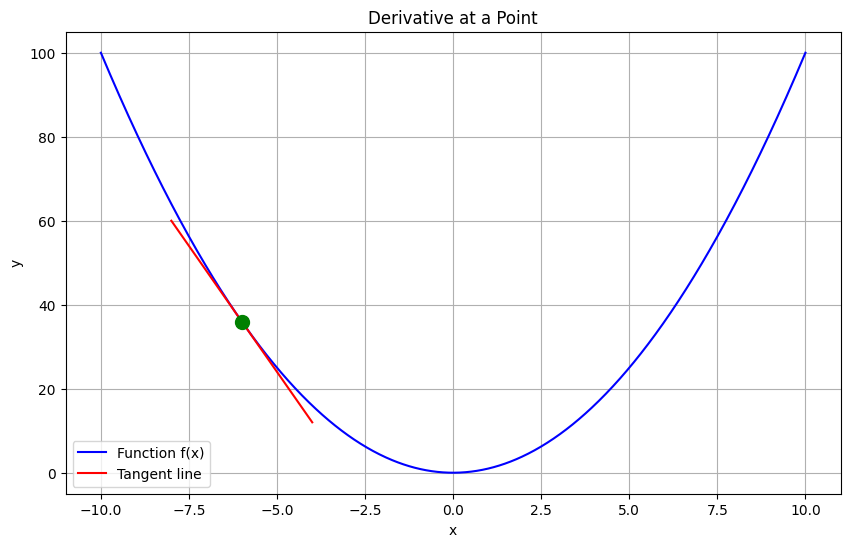

Slope: -12.0000
Intercept: -36.0000


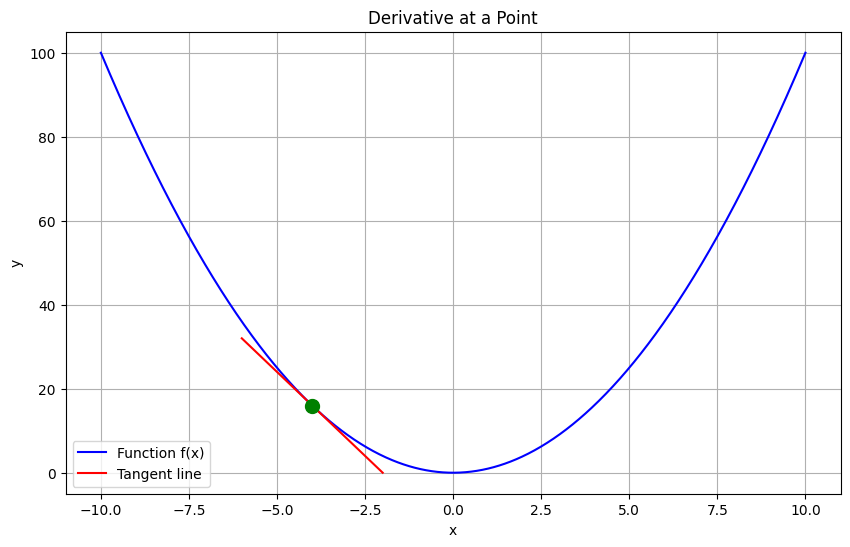

Slope: -8.0000
Intercept: -16.0000


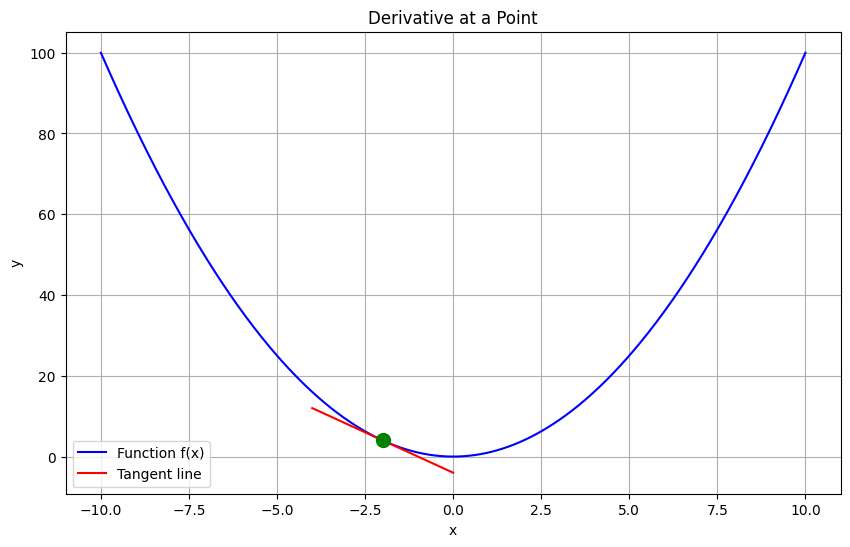

Slope: -4.0000
Intercept: -4.0000


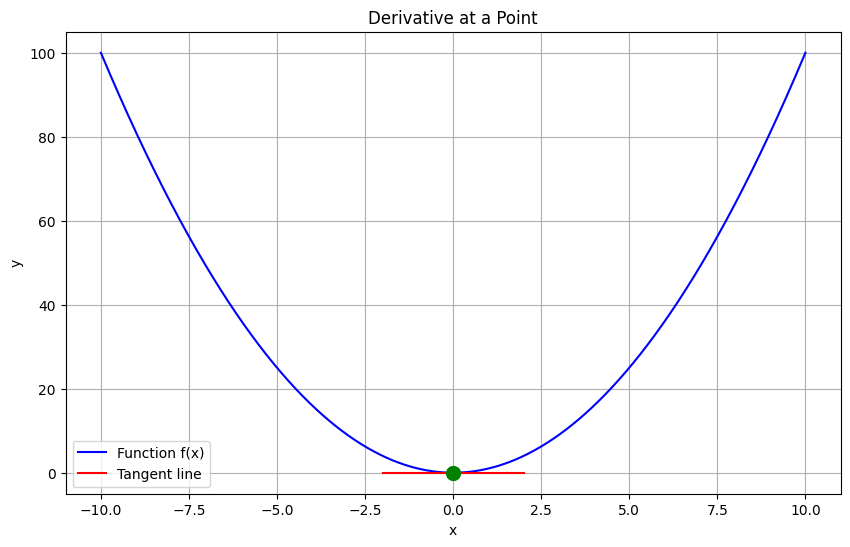

Slope: 0.0000
Intercept: 0.0000


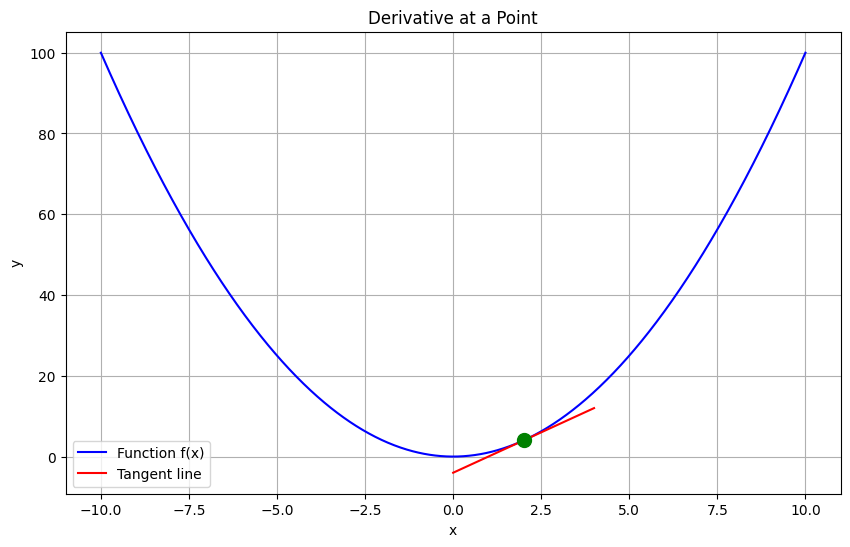

Slope: 4.0000
Intercept: -4.0000


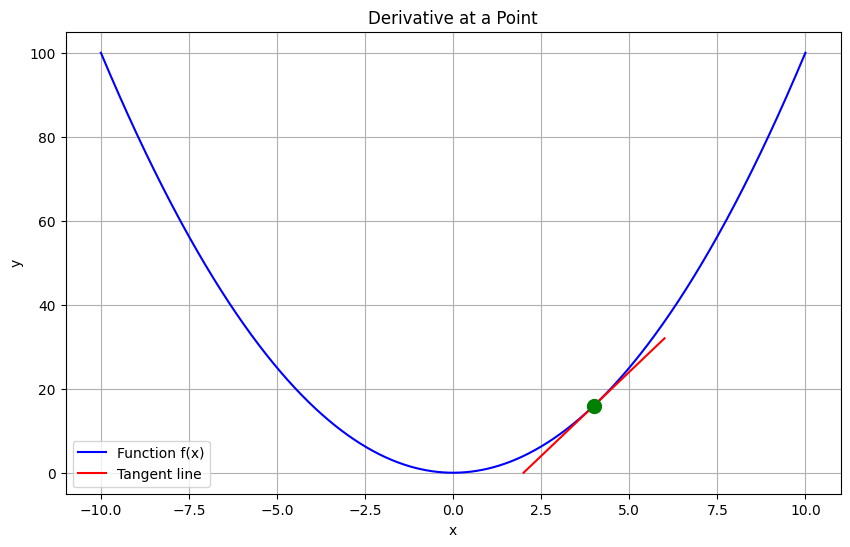

Slope: 8.0000
Intercept: -16.0000


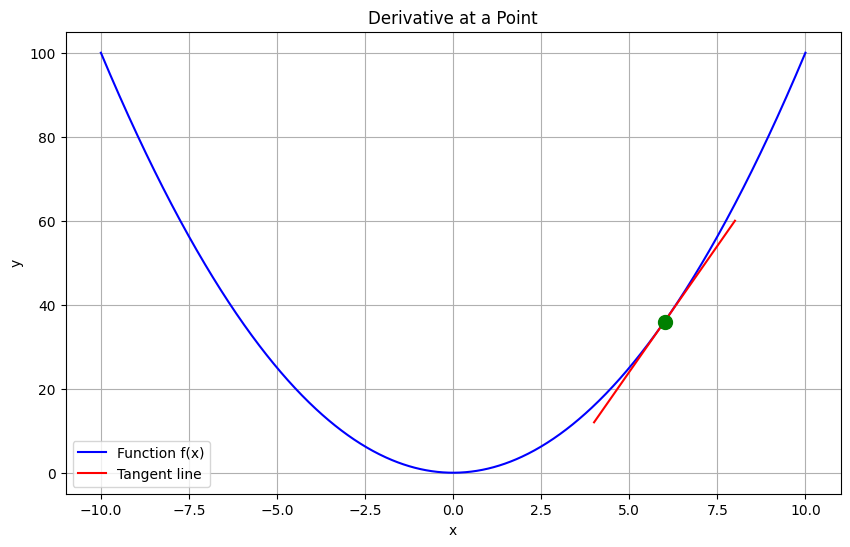

Slope: 12.0000
Intercept: -36.0000


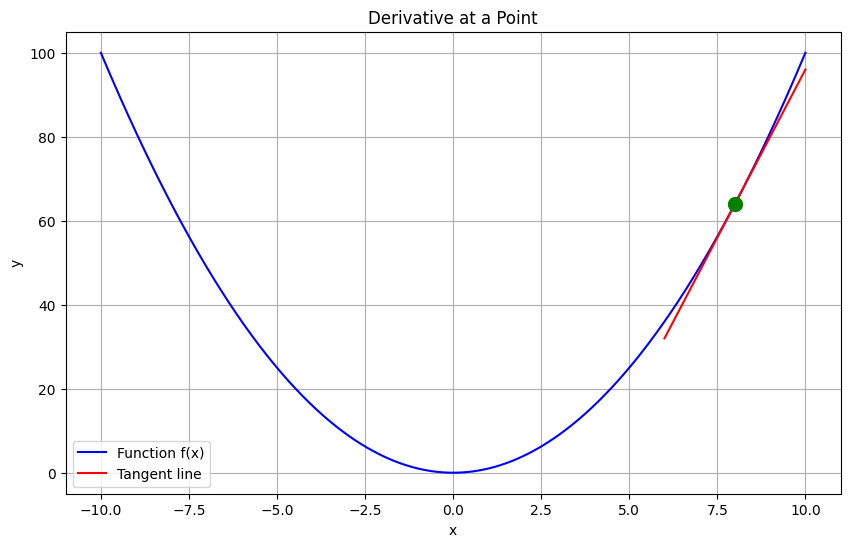

Slope: 16.0000
Intercept: -64.0000


In [9]:
for x in np.arange(-8, 10, 2):
    plot_derivative_at_point(lambda x: x ** 2, x)

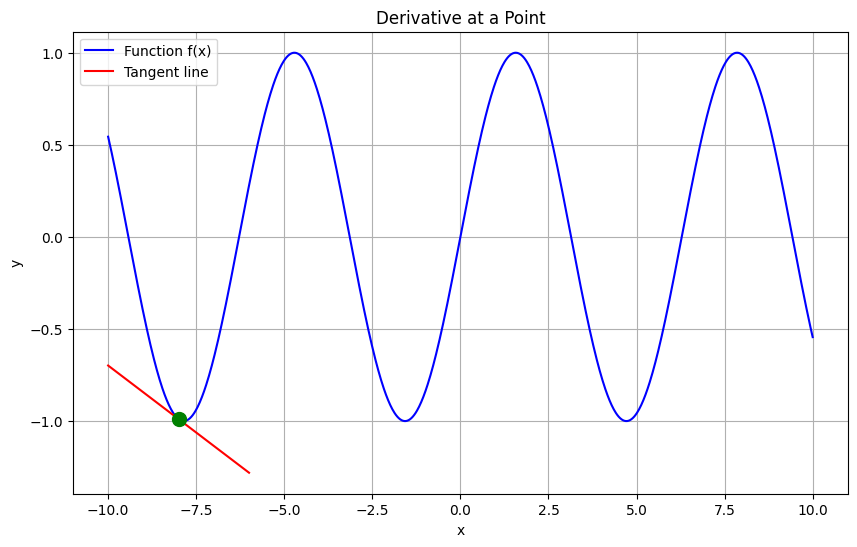

Slope: -0.1455
Intercept: -2.1534


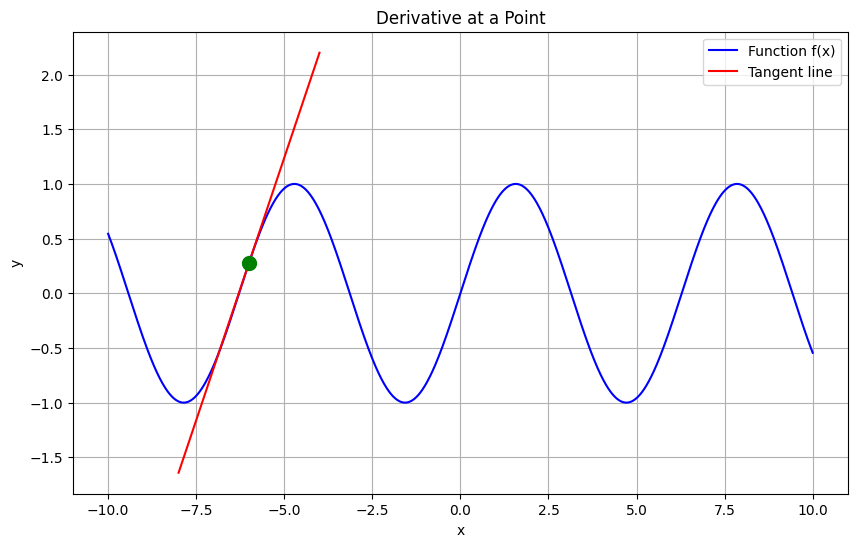

Slope: 0.9602
Intercept: 6.0404


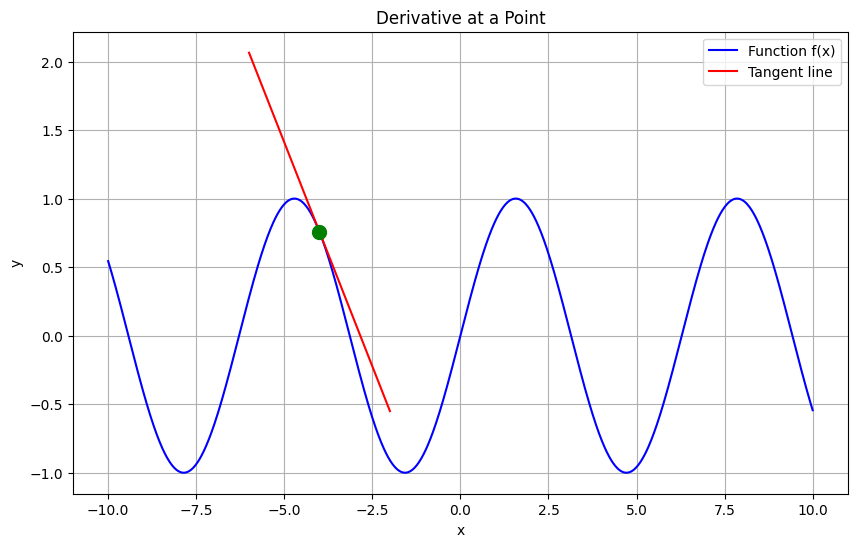

Slope: -0.6536
Intercept: -1.8578


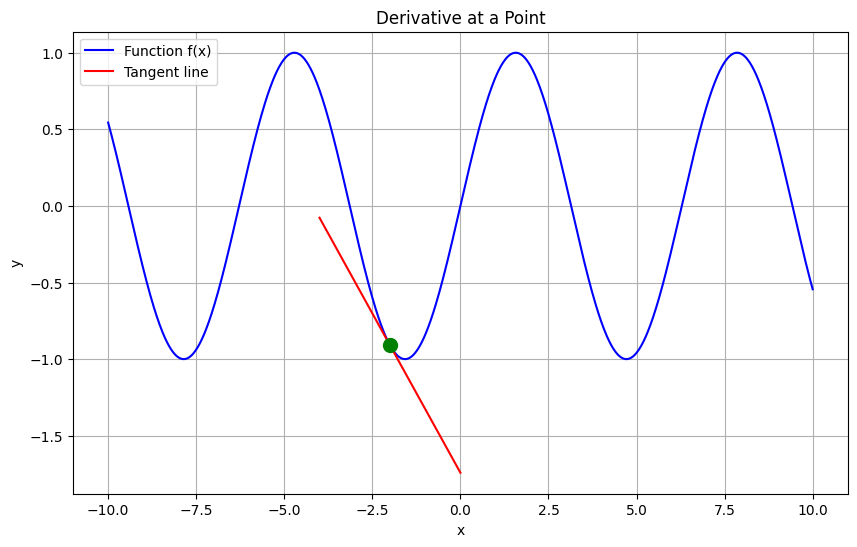

Slope: -0.4161
Intercept: -1.7416


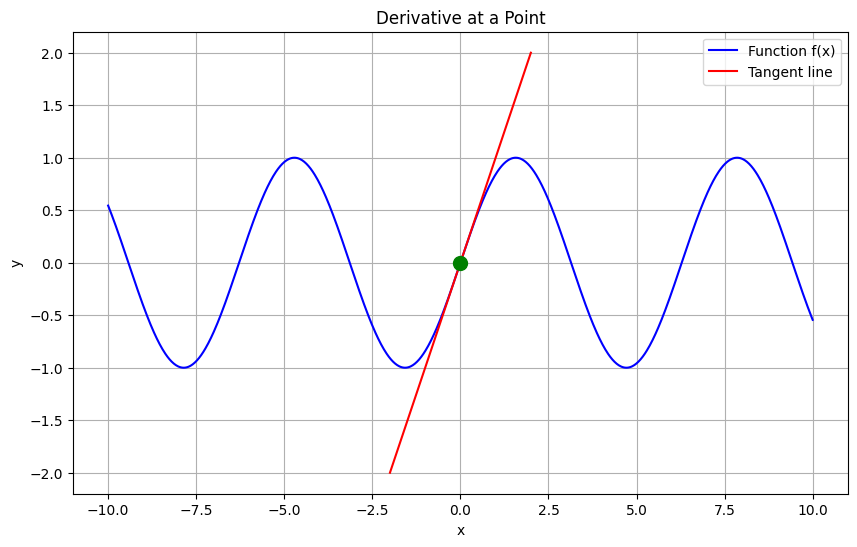

Slope: 1.0000
Intercept: 0.0000


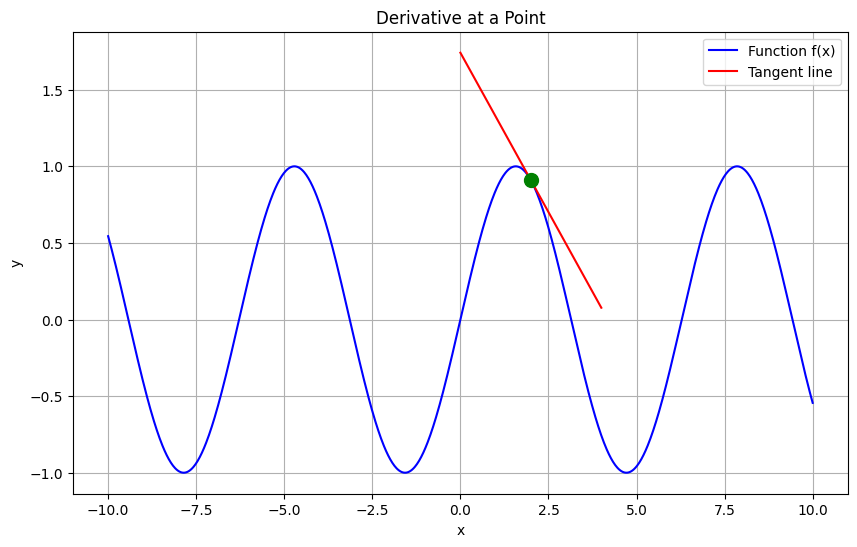

Slope: -0.4161
Intercept: 1.7416


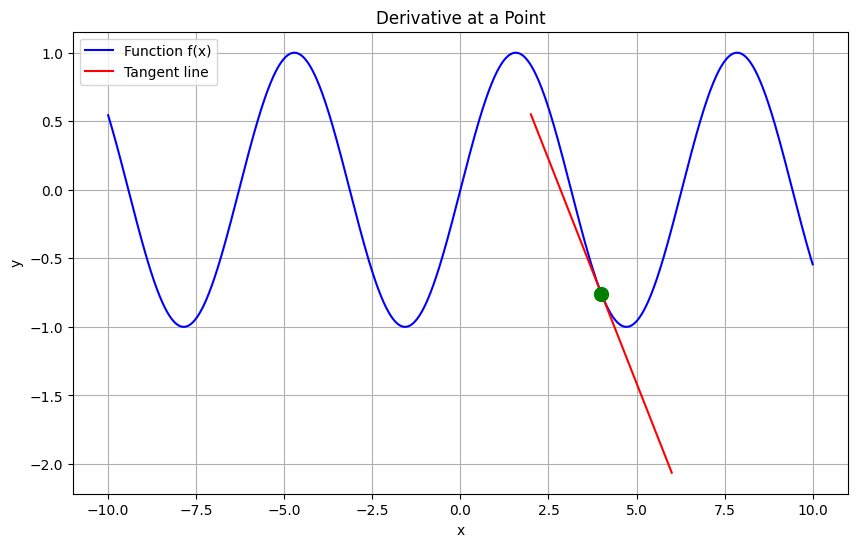

Slope: -0.6536
Intercept: 1.8578


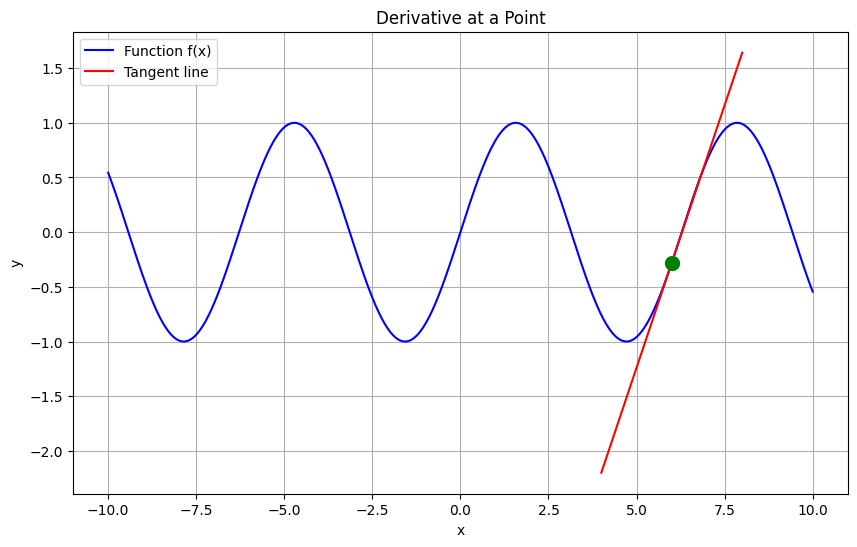

Slope: 0.9602
Intercept: -6.0404


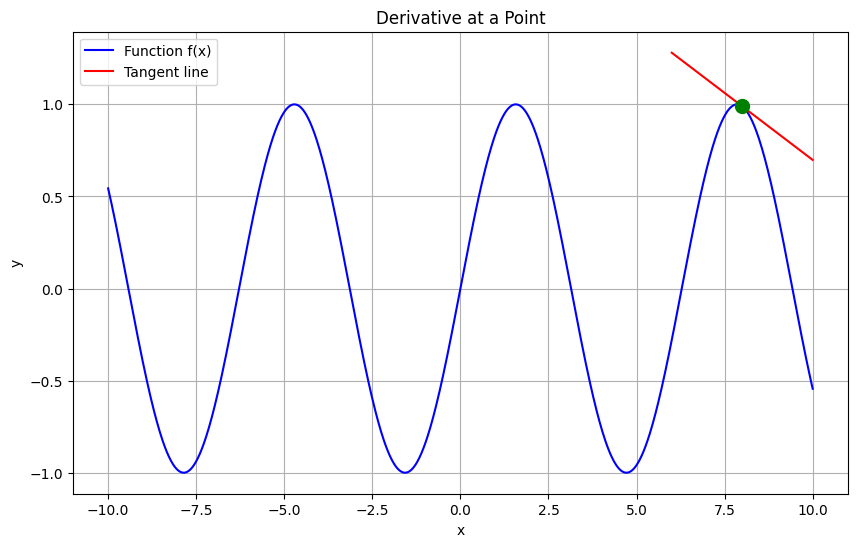

Slope: -0.1455
Intercept: 2.1534


In [10]:
for x in np.arange(-8, 10, 2):
    plot_derivative_at_point(np.sin, x)

Now we have a visual proof that the derivative of a function at a given point is equal to the slope of the tangent line to the function.

### Problem 2. Limits. The Number $e$ as a Limit
We know what limits are, what they mean and how they relate to our tasks. Let's explore a special limit. This one arises from economics but we'll see it has applications throughout science because of its unique properties.

Imagine you're saving money in a bank. Every period, you accumulate [interest](https://en.wikipedia.org/wiki/Compound_interest) on your money. Let's say the bank is very generous and gives you **100% interest every year**.

How much money will you have after one year? Let's say you got $\$1$. After one year, you'll get your interest from the bank and you'll have $\$2$. Your money doubled, which was expected.

How about this offer: **50% interest every 6 months**? Will this be the same, better, or worse?
You start with $\$1$. After 6 months, you'll accumulate $50%$ interest to get $\$1,50$. After 6 more months, you'll get $50\%.1,50 = 0,75$, so your total is $2,25$. You got $\$0,25$ more!

Let's try to exploit the scheme and get rich.

**$100/12\%$ every month**
* January: $1 + 1/12$
* February: $(1 + 1/12) * (1 + 1/12)$
* March: $(1 + 1/12) * (1 + 1/12) * (1 + 1/12)$
* ...

We can see a pattern. Every period, we multiply our money by $1 + 1/12$. So, the final sum will be $$\$1.\left(1+\frac{1}{12}\right)^{12} = \$2,61$$

We did even better. This is always true. The more periods, the more money we accumulate. The more money we have, the more interest we accumulate. And that completes the vicious circle known as money saving :).

Let's try other options:

**$100/52\%$ every week**

$\$1.\left(1+\frac{1}{52}\right)^{52} = \$2,69$

**$100/31556926\%$ every second**

$\$1.\left(1+\frac{1}{31556926}\right)^{31556926} = \$2,718$

Well, there's a slight problem to our world domination plans. Even though we accumulate more and more money, we get *diminishing returns*. For 52 periods we got $2,69$, and for more than 3 million periods we only got like $\$0,02$ more. This pattern will continue.

Now we can ask ourselves, what is the maximum profit we can accumulate for a year? To do this, we can ask
$$ \lim_{n \ \rightarrow \infty}\left(1+\frac{1}{n}\right)^n = ? $$

It turns out this is a constant. It is approximately equal to $2,71828182\dots$. Since it's very useful, it's got a name: $e$, or Euler's number (sometimes called Napier's number). The limit above is **the definition of $e$**.

Why is it so useful? Let's go back to the original problem. In compound interest, the extra amount after every period is proportional to the amount at the start of the period. In other words, **the rate of change of a value is proportional to the value**. This pops out everywhere in nature and business. Some examples include radioactive decay (more atoms $\Rightarrow$ more decays), cooling down a cup of tea (the rate of cooling down depends on the temperature difference between the cup and the room), animal population models (more animals $\Rightarrow$ more babies), infection models, and so on.

To quickly verify the value of $e$, calculate the limit as we defined it above.

In [11]:
def calculate_limit_at_infinity(function):
    """
    Calculates a numerical approximation of the limit of the specified function
    as its parameter goes to infinity
    """
    n = 10 ** np.arange(0, 10)
    return zip(n, function(n))

In [12]:
limits = calculate_limit_at_infinity(lambda x: (1 + 1 / x) ** x)
for limit in limits:
    print(limit)

(np.int64(1), np.float64(2.0))
(np.int64(10), np.float64(2.5937424601000023))
(np.int64(100), np.float64(2.7048138294215285))
(np.int64(1000), np.float64(2.7169239322355936))
(np.int64(10000), np.float64(2.7181459268249255))
(np.int64(100000), np.float64(2.7182682371922975))
(np.int64(1000000), np.float64(2.7182804690957534))
(np.int64(10000000), np.float64(2.7182816941320818))
(np.int64(100000000), np.float64(2.7182817983473577))
(np.int64(1000000000), np.float64(2.7182820520115603))


### Problem 3. Derivatives of Exponential Functions
Use the function you defined in the first problem to plot the derivative of $y = 2^x$.

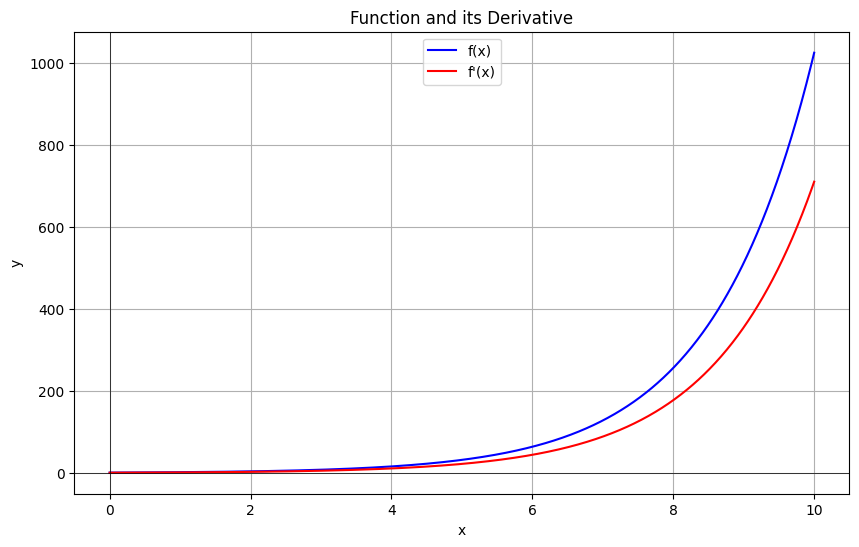

In [13]:
plot_derivative(lambda x: 2 ** x, min_x = 0, max_x = 10)

The function and its derivative look closely related, only the derivative seems to grow a bit slower than the function. Let's confirm that by looking at a broader range:

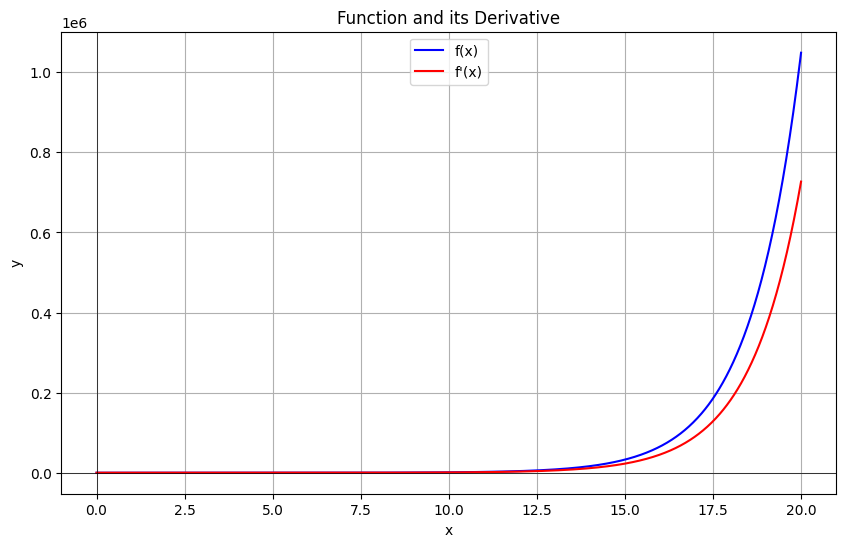

In [14]:
plot_derivative(lambda x: 2 ** x, min_x = 0, max_x = 20)

The same pattern will continue if we try to plot any exponential function, e.g. $y = 3^x$, $y = 4^x$ and so on, if the base of the exponent is greater than 1. If we want to plot, say, $y = 0,5^x$, we'll get a slightly different result. Note that the functions look more or less the same, only their signs are flipped.

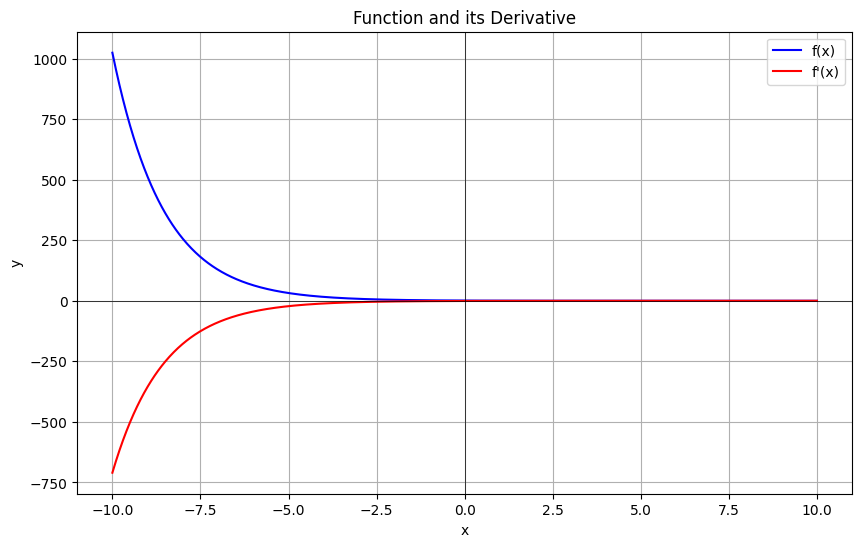

In [15]:
plot_derivative(lambda x: 0.5 ** x)

Very interesting things happen if we plot $y = e^x$:

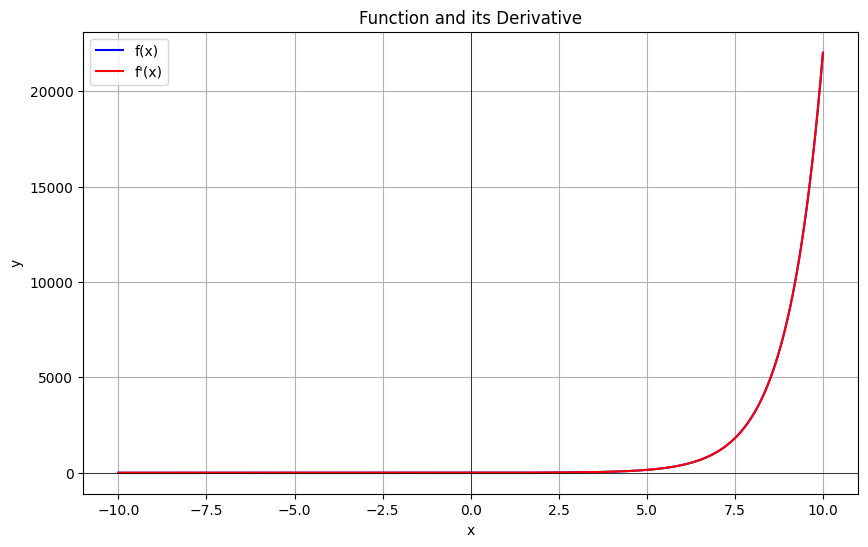

In [16]:
plot_derivative(np.exp)

The plots overlap. You can see that this is true if you plot the function and its derivative with different line widths. This means that

$$ (e^x)' = e^x $$

Also:
$$ (e^x)'' = e^x $$
$$ (e^x)''' = e^x $$
... and so on. This is the only function whose rate of change (derivative) is equal to the function itself. This property makes it even more interesting for science and math.

Also, do you remember that $e^{i\varphi} = \cos(\varphi) + i\sin(\varphi)$? This constant never ceases to amaze.

### Problem 4. Integrals and Area. Changing Variables in Integration
We know that the definition of an integral is the area "between" the function we're integrating, and the x-axis. This gives us a method to calculate integrals. Most integrals can't be solved analytically but have numerical solutions. One such integral is 
$$\int\sin(x^2)dx$$

Note that we can only solve **definite integrals** numerically.

The simplest way to calculate the integral is to apply the definition, like in the case of the derivative. This is called [the trapezoid method](http://www.mathwords.com/t/trapezoid_rule.htm) because the area is approximated as a series of trapezoids.

Write a function which does exactly that. Use `numpy` and vectorization as much as possible.

In [17]:
def calculate_integral(function, x_min, x_max, num_points=5000):
    """
    Calculates a numerical approximation of the definite integral
    of the provided function between x_min and x_max.
    """
    x = np.linspace(x_min, x_max, num_points)

    vectorized_function = np.vectorize(function)
    y = vectorized_function(x)

    dx = (x_max - x_min) / (num_points - 1)

    integral = np.sum((y[:-1] + y[1:]) / 2 * dx)

    return integral

In [18]:
print(calculate_integral(lambda x: x ** 2, 0, 1)) # Should be close to 0.333
print(calculate_integral(lambda x: np.sin(x ** 2), 0, 5)) # Should be close to 0.528

0.33333334000266746
0.5279181074995319


Let's apply our insight to finding the area of a circle. We know the equation of a circle is not a function (it's more like two functions). We can, however be clever. One way is to integrate both of the functions and add them together. Another way is to integrate one and double the area. 

**Note:** We're trying to find the total area of the circle, there is **no negative area** in this particular case.

Another, even more clever way is to look at a quarter of the circle. This is convenient because we may look at the quadrant where $x > 0$ and $y > 0$. So, we'll need to find the area between:
1. $x \ge 0$
2. $y \ge 0$
3. The circle $x^2 + y^2 \le R^2$ (let's fix the radius to be 1)

$\Rightarrow y = \sqrt{R^2 - x^2} = \sqrt{1 - x^2}$

After all of this, we'll need to multiply the result by 4.

$$ S = 4 \int_0^1\sqrt{1 - x^2}dx $$

In [19]:
circle_piece_area = calculate_integral(lambda x: np.sqrt(1 - x ** 2), 0, 1)
total_area = 4 * circle_piece_area
print(total_area)

3.1415893264324883


And we got a value close to $\pi$, which is the real answer.

#### * Optional: Integration in polar coordinates
We can, however, do better. We know that a circle looks much simpler in polar coordinates. Let's now change our viewpoint.

In polar coordinates $(r, \varphi)$, the equation of a circle is

$$ r = R $$

which is our case simplifies to $r = 1$. Note there's no dependence on $\theta$: the radius is the same regardless of the angle. The boundaries for $\theta$ are every possible angle from $0$ to $2\pi$ radians. For $r$, we have $r \ge 0$ and $r \le R$. This translates to the integral:

$$ S = \int_{\theta=0}^{2\pi}\int_{r=0}^R r dr d\theta $$

**Note:** We usually don't write the variables at the bottom of the integral symbol. I've done this just for clarity.

I won't go into details but since there's no dependence on $\theta$, we can simply "separate the integrals" and multiply 
them.

$$ S = \int_{0}^{2\pi}d\theta .\int_{r=0}^R r dr $$

The first one is:
$$ I_1 = \int_0^R r dr = \left.\frac{r^2}{2}\right|_{0}^{R} = \frac{R^2}{2} - \frac{0^2}{2} = \frac{R^2}{2} $$

And the second one is:
$$ I_2 = \int_0^{2\pi}1d\theta = \left.\theta\right|_0^{2\pi} = 2\pi - 0 = 2\pi $$

$$ \Rightarrow  S = I_1I_2 = 2\pi\frac{R^2}{2} = \pi R^2$$

$$ S = \pi R^2$$

### * Problem 5. Taylor Series. Computing Function Value Approximations
Some functions can be really hard to compute, or even impossible. However, there are ways to approximate functions with other functions, which are simpler. The idea is the same as what we already used: we approximated the function with its tangent line to find the derivative at a given point. Research what Taylor series are and how they're used in approximating functions. Derive and implement the Taylor expansions of several functions.
* What is "function approximation"?
* Why can't we compute all functions numerically?
* What are some easy ways to approximate a function near a given point?
* Polynomial functions are very useful approximators. Why? Think about their continuity and derivatives
* What information does the first derivative of a function give us?
    * How does that information generalize to higher-order derivatives (second, third, fourth, etc.)?
* What are Taylor series? Why does it work?
    * Derive the formula
    * What are Maclaurin series? What's the difference?
* Derive some Taylor series expansions. Some common functions are $\sin(x)$ and $\cos(x)$
    * To work with infinite sums, we have to "cut" them somewhere. Why are we allowed to do that? Think about the different terms: one Taylor expansion term doesn't affect the others
    * How are those expansions used in calculators / numerical libraries?
    * Write the code that computes the approximations
    * Test the code
* How many terms do we need?
    * Visualize how the approximation is getting better as we include more terms in the Taylor expansion
    

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial


def taylor_sin(x, num_terms):
    result = 0

    for n in range(num_terms):
        term = (-1)**n * x**(2*n + 1) / factorial(2*n + 1)
        result += term

    return result


def taylor_cos(x, num_terms):
    result = 0

    for n in range(num_terms):
        term = (-1)**n * x**(2*n) / factorial(2*n)
        result += term

    return result

In [21]:
x = 1.0

print("Taylor sin:", taylor_sin(x, 5))
print("NumPy sin: ", np.sin(x))

print("Taylor cos:", taylor_cos(x, 5))
print("NumPy cos: ", np.cos(x))

print("Sin error:", abs(taylor_sin(x, 5) - np.sin(x)))
print("Cos error:", abs(taylor_cos(x, 5) - np.cos(x)))

Taylor sin: 0.8414710097001764
NumPy sin:  0.8414709848078965
Taylor cos: 0.5403025793650793
NumPy cos:  0.5403023058681398
Sin error: 2.4892279903987458e-08
Cos error: 2.734969395401521e-07


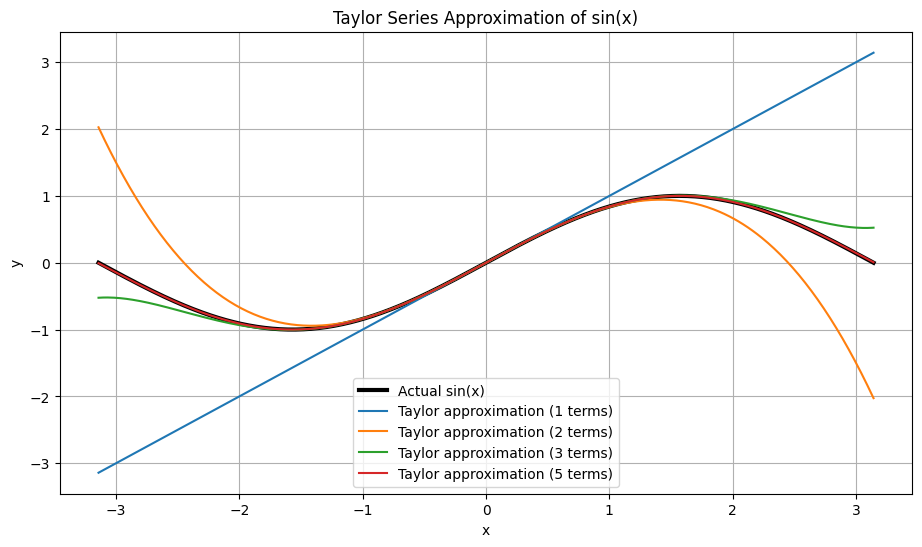

In [22]:
x = np.linspace(-np.pi, np.pi, 500)

plt.figure(figsize=(11, 6))

# Original function
plt.plot(x, np.sin(x),
         label="Actual sin(x)",
         color="black", linewidth=3)

# Taylor approximations
for n in [1, 2, 3, 5]:
    plt.plot(x, taylor_sin(x, n),
             label=f"Taylor approximation ({n} terms)")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Taylor Series Approximation of sin(x)")
plt.grid(True)
plt.legend()
plt.show()

#### Problem 5 — Mathematical explanation and conclusions

A function approximation replaces a difficult expression with a simpler one, typically over a specified interval and with a controlled error. A computer cannot represent arbitrary real numbers exactly, and some functions cannot be evaluated with a finite number of elementary arithmetic operations. Polynomials are convenient approximators because they are continuous, differentiable, and inexpensive to evaluate.

The Taylor polynomial around $a$ matches the function's value and its first $n$ derivatives at $a$:

$$P_n(x)=\sum_{k=0}^{n}\frac{f^{(k)}(a)}{k!}(x-a)^k.$$

The first derivative describes local slope, the second describes how the slope changes, and higher derivatives capture successively finer local behavior. The *Maclaurin* polynomial is the special case $a=0$.

For sine and cosine, the derivatives cycle and give the globally convergent series

$$\sin x=\sum_{k=0}^{\infty}(-1)^k\frac{x^{2k+1}}{(2k+1)!},\qquad \cos x=\sum_{k=0}^{\infty}(-1)^k\frac{x^{2k}}{(2k)!}.$$

The implementation truncates these infinite sums after `num_terms` terms. At $x=1$, five terms give absolute errors of about $2.49\times10^{-8}$ for sine and $2.73\times10^{-7}$ for cosine. The plot shows how adding terms improves the approximation on $[-\pi,\pi]$. For these series, the truncation error tends to zero as the number of terms increases; however, finite-precision arithmetic eventually limits numerical accuracy. Real numerical libraries may additionally use argument reduction and other approximations.

### ** 6. Calculus in Medical Data. Electrocardiography (EKG)
EKG data is basically a 1-dimensional function of time. It records electrical impulses which depend on the state of the heart. How can we analyze EKG data?
* What is EKG data? What is the physical process and what is its interpretation?
    * Provide several EKG plots
    * What are the main parts of an EKG?
* How does the concept of local extrema relate to EKG?
* How does the concept of "convex" / "concave" graphs relate to EKG?

You can take various paths witk EKG data. Some companies, Samsung for example, use a heart rate sensor to measure stress and blood oxygen levels. An algorithm takes data for several seconds or minutes and analyzes it in several ways.
* Optional: Research how you can use EKG or pulse sensor data to measure oxygen in the blood. Have a look [here](https://www.quora.com/How-do-optical-heart-rate-sensors-work) for example
* Optional: How can you use the pulse sensor data to measure stress levels? There are many approaches to this one.
* Optional: Many diseases can be diagnosed from EKG data. Can you train an algorithm to recognize a certain disease? This is related to *time series* analysis

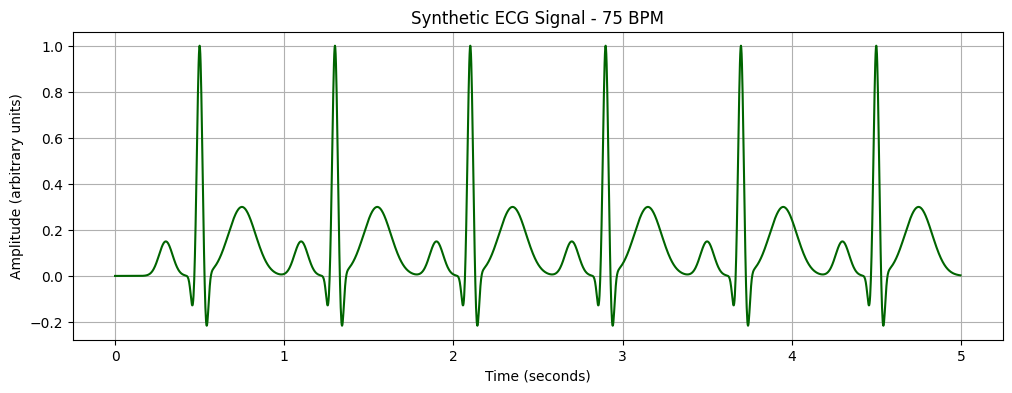

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Time axis: 5 seconds, 500 samples per second
fs = 500
t = np.linspace(0, 5, 5 * fs, endpoint=False)

def gaussian(t, center, width, amplitude):
    return amplitude * np.exp(
        -0.5 * ((t - center) / width) ** 2
    )

def generate_ecg(t, heart_rate=75):
    ecg = np.zeros_like(t)
    beat_interval = 60 / heart_rate

    for beat in np.arange(0.5, t[-1], beat_interval):
        ecg += gaussian(t, beat - 0.20, 0.04, 0.15)  # P
        ecg += gaussian(t, beat - 0.04, 0.012, -0.15) # Q
        ecg += gaussian(t, beat, 0.015, 1.0)         # R
        ecg += gaussian(t, beat + 0.04, 0.012, -0.25) # S
        ecg += gaussian(t, beat + 0.25, 0.08, 0.30)  # T

    return ecg

ecg = generate_ecg(t)

plt.figure(figsize=(12, 4))
plt.plot(t, ecg, color="darkgreen")
plt.title("Synthetic ECG Signal - 75 BPM")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (arbitrary units)")
plt.grid(True)
plt.show()

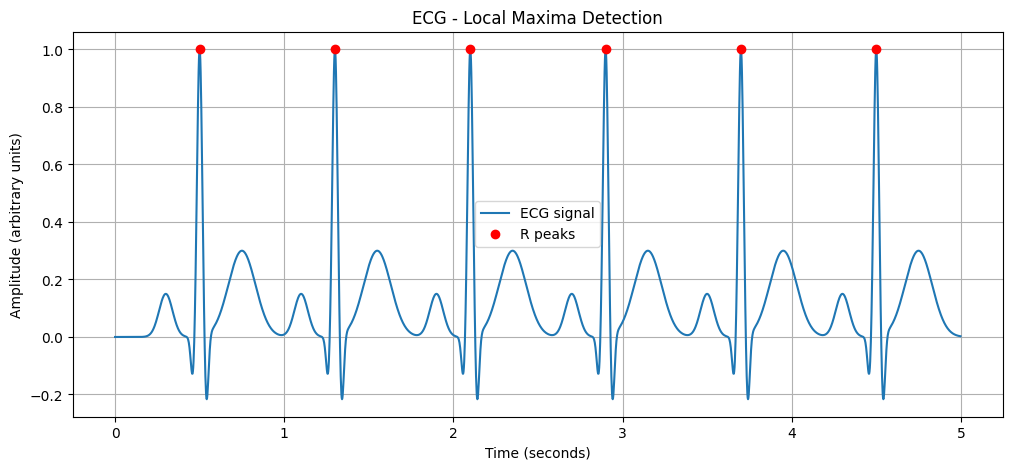

Estimated heart rate: 75.0 BPM


In [24]:
from scipy.signal import find_peaks

# First and second derivatives
first_derivative = np.gradient(ecg, t)
second_derivative = np.gradient(first_derivative, t)

# Detect prominent R peaks
peaks, properties = find_peaks(
    ecg,
    height=0.7,
    distance=int(0.5 * fs)
)

plt.figure(figsize=(12, 5))

plt.plot(t, ecg, label="ECG signal")
plt.plot(t[peaks], ecg[peaks], "ro", label="R peaks")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (arbitrary units)")
plt.title("ECG - Local Maxima Detection")
plt.legend()
plt.grid(True)
plt.show()

# Calculate heart rate from R-R intervals
rr_intervals = np.diff(t[peaks])

if len(rr_intervals) > 0:
    heart_rate = 60 / np.mean(rr_intervals)
    print(f"Estimated heart rate: {heart_rate:.1f} BPM")

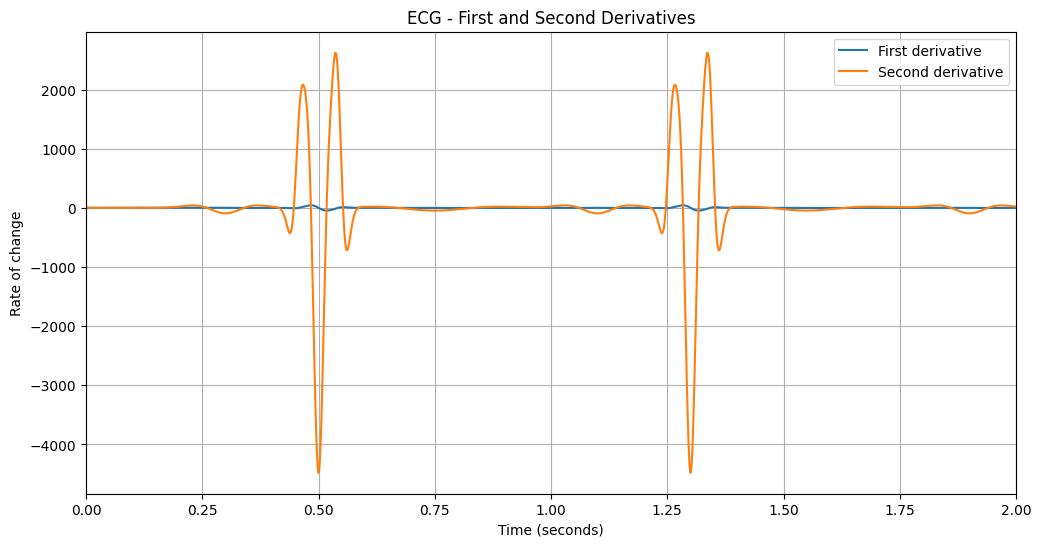

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(t, first_derivative, label="First derivative")
plt.plot(t, second_derivative, label="Second derivative")

plt.xlim(0, 2)
plt.xlabel("Time (seconds)")
plt.ylabel("Rate of change")
plt.title("ECG - First and Second Derivatives")
plt.legend()
plt.grid(True)
plt.show()

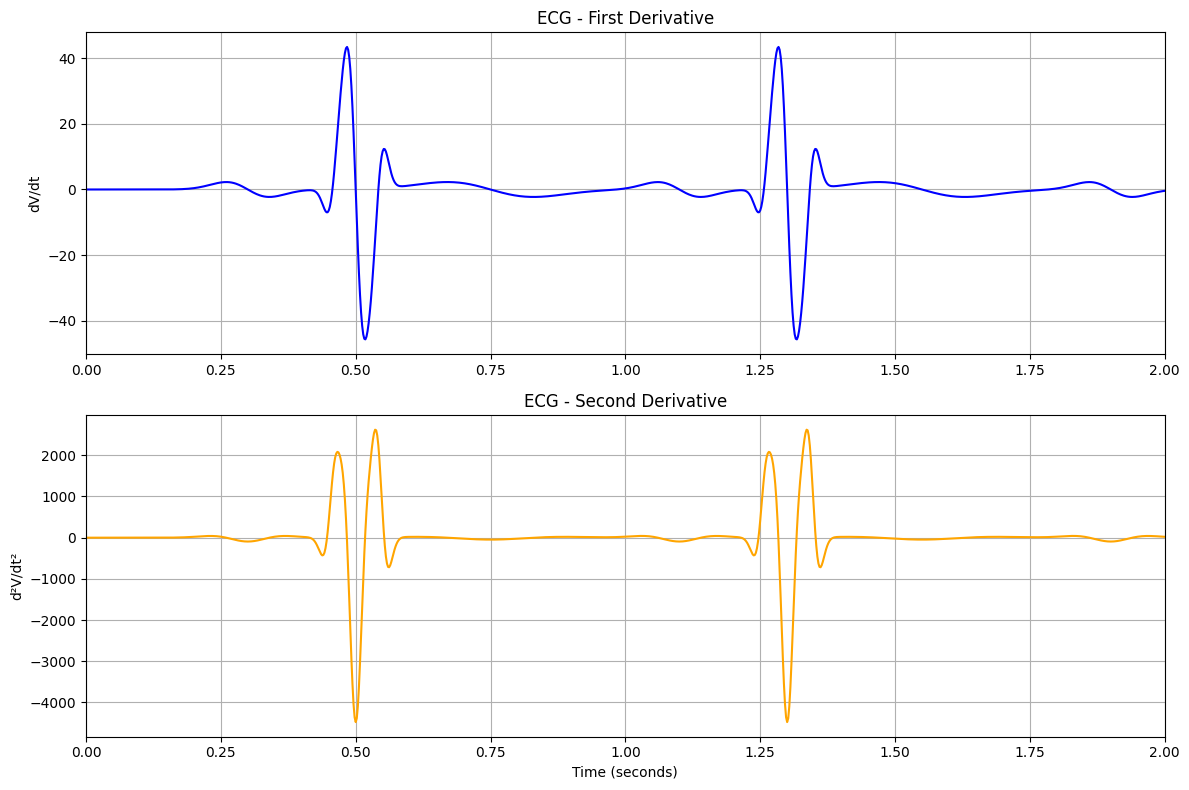

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(t, first_derivative, color="blue")
axes[0].set_title("ECG - First Derivative")
axes[0].set_ylabel("dV/dt")
axes[0].set_xlim(0, 2)
axes[0].grid(True)

axes[1].plot(t, second_derivative, color="orange")
axes[1].set_title("ECG - Second Derivative")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("d²V/dt²")
axes[1].set_xlim(0, 2)
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### Problem 6 — EKG interpretation and calculus

An electrocardiogram (ECG/EKG) records voltage differences produced by the electrical activity of the heart over time. The **P wave** is associated with atrial depolarization, the **QRS complex** with ventricular depolarization, and the **T wave** with ventricular repolarization. An R–R interval measures the time between consecutive R peaks.

In a sufficiently smooth signal $V(t)$, local maxima and minima can be found by analyzing changes in the sign of $V'(t)$. The second derivative $V''(t)$ describes how the slope changes: positive values indicate local upward curvature and negative values downward curvature. Inflection points can occur when this curvature changes sign. Differentiation also amplifies noise, so practical ECG analysis requires preprocessing and robust peak detection.

The notebook generates a **synthetic**, idealized ECG-like waveform using Gaussian components, not a patient recording. `scipy.signal.find_peaks` locates its R peaks. With an R–R interval of approximately $0.8$ seconds, the estimated heart rate is $60/0.8=75$ beats per minute. The derivative plots illustrate rapid variation near the QRS complexes; the separate panels are preferable because the first and second derivatives have different scales and units.

**Optional applications:** Pulse oximetry estimates oxygen saturation using optical measurements at different wavelengths (typically red and infrared), rather than from a standard ECG trace alone. Heart-rate variability can contribute to stress-related research, but it is not a standalone stress diagnosis. Arrhythmia classification from labeled ECG time series is a possible machine-learning application requiring representative data and clinical validation. No medical diagnosis is attempted here.

### ** 7. Physics Engine
Use your knowledge of vectors, algebra and calculus to create a physics engine. You can use this for many things. One example is computer games. Another example is computer simulation.

Don't forget to provide details about your calculations and implementations. 
* Implement vectors and operations
* Implement visualization
* Implement Newtonian mechanics with forces as vectors acting on material points
* Implement another physical process: e.g. collision detection. This should take into account momentum and the law of conservation of momentum
    * You can also implement other physical phenomena (e.g. heat transfer, reflection of light, etc.), as you need.

In [27]:
import numpy as np
import matplotlib.pyplot as plt

class Vector2D:
    def __init__(self, x, y):
        self.x = float(x)
        self.y = float(y)

    def __add__(self, other):
        return Vector2D(self.x + other.x, self.y + other.y)

    def __sub__(self, other):
        return Vector2D(self.x - other.x, self.y - other.y)

    def __mul__(self, scalar):
        return Vector2D(self.x * scalar, self.y * scalar)

    __rmul__ = __mul__

    def __truediv__(self, scalar):
        return Vector2D(self.x / scalar, self.y / scalar)

    def magnitude(self):
        return np.sqrt(self.x**2 + self.y**2)

    def __repr__(self):
        return f"Vector2D({self.x:.3f}, {self.y:.3f})"


# Test vector operations
v1 = Vector2D(3, 4)
v2 = Vector2D(1, 2)

print("Addition:", v1 + v2)
print("Subtraction:", v1 - v2)
print("Multiplication:", v1 * 2)
print("Magnitude:", v1.magnitude())

Addition: Vector2D(4.000, 6.000)
Subtraction: Vector2D(2.000, 2.000)
Multiplication: Vector2D(6.000, 8.000)
Magnitude: 5.0


In [28]:
class Particle:
    def __init__(self, mass, position, velocity):
        if mass <= 0:
            raise ValueError("Mass must be positive")

        self.mass = mass
        self.position = position
        self.velocity = velocity
        self.force = Vector2D(0, 0)

    def apply_force(self, force):
        self.force = self.force + force

    def update(self, dt):
        acceleration = self.force / self.mass

        self.velocity = self.velocity + acceleration * dt
        self.position = self.position + self.velocity * dt

        self.force = Vector2D(0, 0)

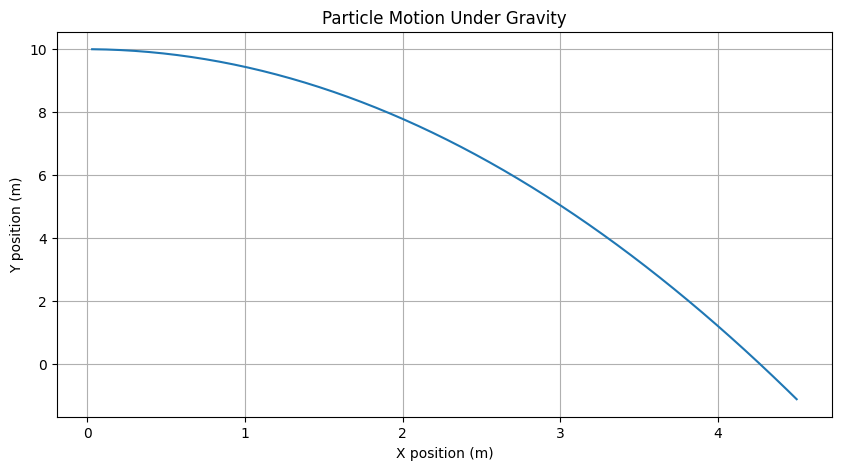

In [29]:
particle = Particle(
    mass=2,
    position=Vector2D(0, 10),
    velocity=Vector2D(3, 0)
)

dt = 0.01
gravity = Vector2D(0, -9.81)

positions = []

for step in range(150):
    particle.apply_force(gravity * particle.mass)
    particle.update(dt)

    positions.append((
        particle.position.x,
        particle.position.y
    ))

positions = np.array(positions)

plt.figure(figsize=(10, 5))
plt.plot(positions[:, 0], positions[:, 1])
plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("Particle Motion Under Gravity")
plt.grid(True)
plt.show()

In [30]:
def elastic_collision(m1, m2, v1, v2):
    if m1 <= 0 or m2 <= 0:
        raise ValueError("Masses must be positive")

    new_v1 = ((m1 - m2) * v1 + 2 * m2 * v2) / (m1 + m2)
    new_v2 = (2 * m1 * v1 + (m2 - m1) * v2) / (m1 + m2)

    return new_v1, new_v2


# Example
m1, m2 = 2, 3
v1, v2 = 4, -2

momentum_before = m1 * v1 + m2 * v2

new_v1, new_v2 = elastic_collision(m1, m2, v1, v2)

momentum_after = m1 * new_v1 + m2 * new_v2

print("Velocity 1 after collision:", new_v1)
print("Velocity 2 after collision:", new_v2)
print("Momentum before:", momentum_before)
print("Momentum after:", momentum_after)

print("Momentum conserved:",
      np.isclose(momentum_before, momentum_after))

Velocity 1 after collision: -3.2
Velocity 2 after collision: 2.8
Momentum before: 2
Momentum after: 1.9999999999999982
Momentum conserved: True


In [31]:
energy_before = 0.5 * m1 * v1**2 + 0.5 * m2 * v2**2

energy_after = (
    0.5 * m1 * new_v1**2
    + 0.5 * m2 * new_v2**2
)

print("Energy before:", energy_before)
print("Energy after:", energy_after)

print("Energy conserved:",
      np.isclose(energy_before, energy_after))


Energy before: 22.0
Energy after: 22.0
Energy conserved: True


Collision detected at t = 1.234 s


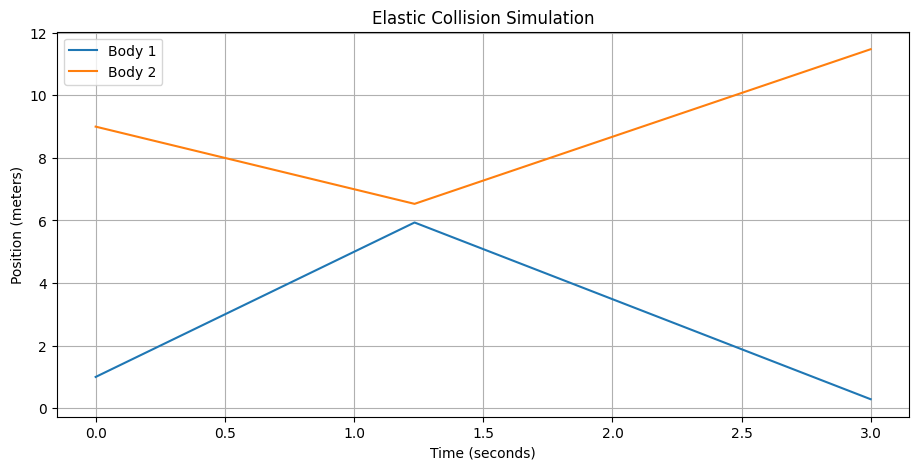

Final velocity body 1: -3.2
Final velocity body 2: 2.8


In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Initial parameters
m1, m2 = 2.0, 3.0
x1, x2 = 1.0, 9.0
v1, v2 = 4.0, -2.0

r1, r2 = 0.3, 0.3
dt = 0.001
total_time = 3.0

time_values = []
positions1 = []
positions2 = []

collision_detected = False

for t in np.arange(0, total_time, dt):

    # Save positions
    time_values.append(t)
    positions1.append(x1)
    positions2.append(x2)

    # Move bodies
    x1 += v1 * dt
    x2 += v2 * dt

    # Collision detection
    if not collision_detected and abs(x2 - x1) <= r1 + r2:

        # Check if bodies are approaching
        if (x2 - x1) * (v2 - v1) < 0:
            v1, v2 = elastic_collision(m1, m2, v1, v2)
            collision_detected = True
            print(f"Collision detected at t = {t + dt:.3f} s")

# Visualization
plt.figure(figsize=(11, 5))

plt.plot(time_values, positions1, label="Body 1")
plt.plot(time_values, positions2, label="Body 2")

plt.xlabel("Time (seconds)")
plt.ylabel("Position (meters)")
plt.title("Elastic Collision Simulation")
plt.legend()
plt.grid(True)
plt.show()

print("Final velocity body 1:", v1)
print("Final velocity body 2:", v2)

#### Problem 7 — Physics engine: implementation, calculations, and limitations

The notebook implements a simple educational physics engine. `Vector2D` supports vector addition, subtraction, scalar multiplication/division, and magnitude $|\vec v|=\sqrt{v_x^2+v_y^2}$. The `Particle` class stores mass, position, velocity, and accumulated force.

**Newtonian dynamics.** Newton's second law gives $\vec a=\vec F/m$. With time step $\Delta t$, the *semi-implicit Euler* update is

$$\vec v_{k+1}=\vec v_k+\vec a_k\Delta t,\qquad \vec x_{k+1}=\vec x_k+\vec v_{k+1}\Delta t.$$

A constant downward gravitational acceleration produces the plotted approximately parabolic trajectory. The numerical trajectory may deviate slightly from the analytic solution because the time step is finite.

**Collision detection.** In the one-dimensional demonstration, bodies of radii $r_1,r_2$ make contact when $|x_2-x_1|\le r_1+r_2$. The implementation additionally checks that they are approaching. At contact, the `elastic_collision` function computes their new velocities from the one-dimensional perfectly elastic collision equations.

**Conservation laws.** For an isolated two-body collision, momentum and kinetic energy satisfy

$$m_1v_1+m_2v_2=m_1v'_1+m_2v'_2,$$

$$\frac12m_1v_1^2+\frac12m_2v_2^2=\frac12m_1(v'_1)^2+\frac12m_2(v'_2)^2.$$

For $m_1=2\,\mathrm{kg}$, $m_2=3\,\mathrm{kg}$, $v_1=4\,\mathrm{m/s}$, and $v_2=-2\,\mathrm{m/s}$, the calculated post-collision velocities are $-3.2$ and $2.8\,\mathrm{m/s}$. Total momentum is $2\,\mathrm{kg\,m/s}$ and total kinetic energy is $22\,\mathrm{J}$ both before and after the collision, up to floating-point rounding. The simulation detects contact at approximately $t=1.234\,\mathrm{s}$.

**Limitations.** Motion under forces is demonstrated in two dimensions, but the collision solver is one-dimensional. The contact check uses discrete time steps and does not compute the exact continuous collision time or correct penetration. Rotational dynamics, friction, multiple simultaneous contacts, and arbitrary 2D collision response are outside this example. The engine is suitable for demonstrating calculus and conservation laws, not yet a production physics simulator.

**Conclusion.** These experiments connect vector algebra, derivatives, numerical integration, and conservation principles with executable Python simulations.